# Hotel Booking Demand — EDA for the Revenue Dashboard

Step 3 of the Data App exercise: a quick EDA to decide **what goes on the dashboard and what stays off**.
Runs on Kaggle (dataset uploaded as `hotel-booking-demand`); also runs locally next to `hotels.csv`.

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

hits = glob.glob("/kaggle/input/**/hotels.csv", recursive=True)
df = pd.read_csv(hits[0] if hits else "hotels.csv")

print(df.shape)
print(df.dtypes.value_counts())
print("\nmissing values (columns with any):")
print(df.isna().sum()[df.isna().sum() > 0])
print("\narrival years:", sorted(df["arrival_date_year"].unique()))
print("months present:", sorted(df["arrival_date_month"].unique())[:3], "...")

(119390, 32)
int64      16
str        12
float64     4
Name: count, dtype: int64

missing values (columns with any):
children         4
country        488
agent        16340
company     112593
dtype: int64

arrival years: [np.int64(2015), np.int64(2016), np.int64(2017)]
months present: ['April', 'August', 'December'] ...


**What one row is:** one booking (119,390 bookings, 32 columns, two hotels). Nothing is missing for the two
targets we care about (`is_canceled`, `adr`); `company` is empty in 94% of rows and `agent` in 14%.

In [2]:
MONTHS = ["January", "February", "March", "April", "May", "June",
          "July", "August", "September", "October", "November", "December"]
df["arrival_month"] = pd.Categorical(df["arrival_date_month"], MONTHS, ordered=True)

print("bookings:", f"{len(df):,}")
print("cancellation rate:", f"{df['is_canceled'].mean():.1%}")
print("average nightly rate (ADR):", f"${df['adr'].mean():.2f}")
print("\nby hotel:")
print(df.groupby("hotel").agg(bookings=("is_canceled", "size"),
                              cancel_rate=("is_canceled", "mean"),
                              adr=("adr", "mean")).round(3))
print("\nADR: rows <= 0 (likely complimentary):", int((df["adr"] <= 0).sum()),
      "| max:", df["adr"].max())
print("rows per year:", df["arrival_date_year"].value_counts().sort_index().to_dict())

bookings: 119,390
cancellation rate: 37.0%
average nightly rate (ADR): $101.83

by hotel:
              bookings  cancel_rate      adr
hotel                                       
City Hotel       79330        0.417  105.304
Resort Hotel     40060        0.278   94.953

ADR: rows <= 0 (likely complimentary): 1960 | max: 5400.0
rows per year: {2015: 21996, 2016: 56707, 2017: 40687}


**Already the two hotels look different** (42% vs 28% cancellation) — so the hotel must be a filter, not a
colour on a mixed chart. Note the data is a partial-year snapshot (2015 from July, 2017 to August) and 1,960 rows
have ADR ≤ 0 (complimentary stays) with one 5,400 outlier: no year-over-year metric on the dashboard.

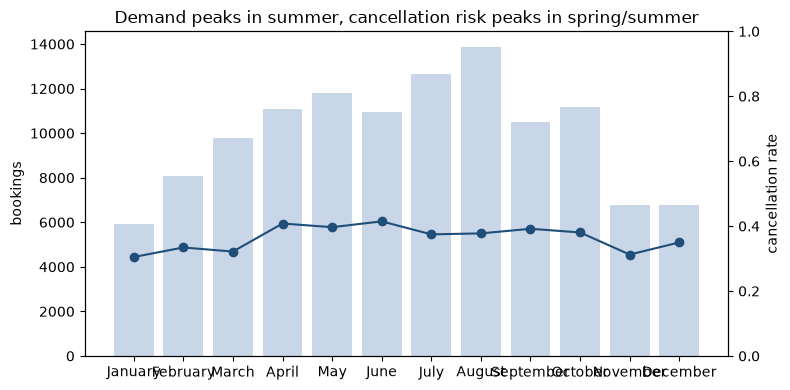

               bookings  cancel_rate
arrival_month                       
January            5929        0.305
February           8068        0.334
March              9794        0.322
April             11089        0.408
May               11791        0.397
June              10939        0.415
July              12661        0.375
August            13877        0.378
September         10508        0.392
October           11160        0.380
November           6794        0.312
December           6780        0.350


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
t = df.groupby("arrival_month", observed=True).agg(bookings=("is_canceled", "size"),
                                                   cancel_rate=("is_canceled", "mean"))
ax.bar(t.index.astype(str), t["bookings"], color="#c9d6e8", label="bookings")
ax2 = ax.twinx()
ax2.plot(t.index.astype(str), t["cancel_rate"], color="#1f4e79", marker="o", label="cancel rate")
ax2.set_ylim(0, 1); ax2.set_ylabel("cancellation rate"); ax.set_ylabel("bookings")
ax.set_title("Demand peaks in summer, cancellation risk peaks in spring/summer")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

print(t.round(3))

**Finding:** bookings peak Jun–Aug (rate season), but the cancellation rate also peaks Apr–Jun (~40–41%)
versus ~30% in winter. Volume and risk arrive together, so the manager needs both numbers, not just revenue.

lead_time_bucket
<= 1 week           0.110
1 week - 1 month    0.279
1-3 months          0.377
3-6 months          0.447
> 6 months          0.570
Name: is_canceled, dtype: float64


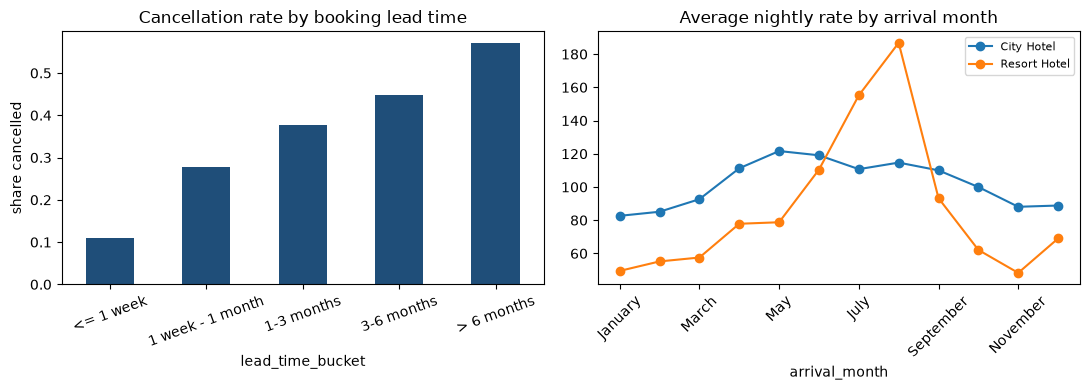

In [4]:
df["lead_time_bucket"] = pd.cut(df["lead_time"], [0, 7, 30, 90, 180, 1000],
                                 labels=["<= 1 week", "1 week - 1 month", "1-3 months",
                                         "3-6 months", "> 6 months"])
lt = df.groupby("lead_time_bucket", observed=True)["is_canceled"].mean()
print(lt.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lt.plot.bar(ax=axes[0], color="#1f4e79")
axes[0].set_title("Cancellation rate by booking lead time")
axes[0].set_ylabel("share cancelled"); axes[0].tick_params(axis="x", rotation=20)

adr = df.groupby(["arrival_month", "hotel"], observed=True)["adr"].mean().unstack()
adr.plot(ax=axes[1], marker="o")
axes[1].set_title("Average nightly rate by arrival month")
axes[1].tick_params(axis="x", rotation=45); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Finding:** bookings made more than 6 months ahead cancel 57% of the time versus 11% for last-week
bookings — the far-ahead, cheap-to-cancel reservations are what drives the risk. ADR is strongly seasonal
($70 in winter, $140 in August), which is why it belongs at the top as a level rather than as another chart.

In [5]:
print("cancellation by country - top 8 by volume:")
top = df["country"].value_counts().head(8).index
print(df[df["country"].isin(top)].groupby("country")["is_canceled"]
      .agg(bookings="size", cancel_rate="mean").round(3).sort_values("cancel_rate", ascending=False))

print("\ncancellation by deposit type (the trap):")
print(df.groupby("deposit_type")["is_canceled"].agg(bookings="size", cancel_rate="mean").round(3))

print("\ncancellation by market segment:")
print(df.groupby("market_segment")["is_canceled"].agg(bookings="size", cancel_rate="mean")
      .round(3).sort_values("cancel_rate", ascending=False).head(5))

print("\nnegative ADR check - by month, share of rows with adr <= 0:")
print(df.assign(neg=df["adr"] <= 0).groupby("arrival_month", observed=True)["neg"].mean().round(3).to_dict())

cancellation by country - top 8 by volume:
         bookings  cancel_rate
country                       
PRT         48590        0.566
ITA          3766        0.354
ESP          8568        0.254
IRL          3375        0.247
BEL          2342        0.202
GBR         12129        0.202
FRA         10415        0.186
DEU          7287        0.167

cancellation by deposit type (the trap):
              bookings  cancel_rate
deposit_type                       
No Deposit      104641        0.284
Non Refund       14587        0.994
Refundable         162        0.222

cancellation by market segment:
                bookings  cancel_rate
market_segment                       
Undefined              2        1.000
Groups             19811        0.611
Online TA          56477        0.367
Offline TA/TO      24219        0.343
Aviation             237        0.219

negative ADR check - by month, share of rows with adr <= 0:
{'January': 0.022, 'February': 0.018, 'March': 0.016, 'April': 0.

## What this EDA settled

**On the dashboard:** three headline numbers (bookings, cancellation rate, ADR) and two charts that explain
the cancellation number — cancellation by arrival month and by lead time. One filter: the hotel.

**Cut, with reasons:**
1. **Cancellation by country** — differs a lot between markets (a nice EDA result) but a revenue manager of one
   hotel cannot act on guest nationality in the weekly pricing meeting.
2. **ADR by month as a third chart** — seasonal, but the decision on this page is cancellation risk; a third
   chart only pushes the two that matter further down.
3. **Cancellation by deposit type** — "Non Refund" deposits cancel 99.4% of the time. Displaying it would tell the
   manager something false ("deposits cause cancellations"); the pattern comes from how this dataset records
   automatic/group bookings, and we cannot explain it from the data, so it stays off.

**Caveats carried onto the page:** partial first and last years (no YoY metric), ADR is a plain mean including
1,960 complimentary (ADR ≤ 0) rows and one $5,400 outlier, and the two hotels must never be mixed — hence the
hotel filter and the data-period caption listing the production refresh frequency.